# 04 · Results figures

Shows every figure and the hypothesis summary for SD vs NS. All plotting code is in `analysis/figures.py`; this notebook only calls it. Figures are saved to `results/figures/` together with `captions.md`.

Inputs: `python -m batch.run_batch` and `python -m analysis.stats` must have been run. Eyes open is the primary analysis, eyes closed secondary; they are never pooled. Group-level spectral differences only, with no clinical interpretation.

In [1]:
import sys
from pathlib import Path

PROJECT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(PROJECT))

import pandas as pd
from IPython.display import Image, Markdown, display
from analysis.figures import make_all
from analysis.hypotheses import HYPOTHESES

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda v: f'{v:.3g}')

figures = make_all(PROJECT / 'results')
captions = (PROJECT / 'results' / 'figures' / 'captions.md').read_text(encoding='utf-8')
list(figures)

['topomap_open',
 'psd_regions_open',
 'paired_open',
 'topomap_closed',
 'psd_regions_closed',
 'paired_closed',
 'theta_beta',
 'hypothesis_summary']

## Hypotheses

Defined in `analysis/hypotheses.md` / `analysis/hypotheses.py` (references are TODO until verified).

In [2]:
pd.DataFrame([dict(id=h.id, bands=', '.join(h.bands), regions=', '.join(h.regions),
                   expected=h.direction or 'none', eyes_focus=h.eyes_focus,
                   exploratory=h.exploratory, statement=h.statement) for h in HYPOTHESES])

,id,bands,regions,expected,eyes_focus,exploratory,statement
0,H1,"delta, theta","frontal, central",+,both,False,"Delta and theta power increase after SD, large..."
1,H2,alpha,"parietal, occipital",-,closed,False,"Alpha power decreases after SD, largest over p..."
2,H3,theta/beta,frontal,+,both,False,The frontal theta/beta ratio increases after SD.
3,H4,beta,"frontal, central, temporal, parietal, occipital",none,both,True,"Beta power: exploratory, no directional predic..."


## Hypothesis summary

`supported` = expected sign and corrected p < .05; `opposite` = significant in the other direction; `largest_region` = region with the largest |dz|.

In [3]:
summary = figures['hypothesis_summary']
summary[['hypothesis', 'eyes', 'band', 'region', 'expected', 'observed', 'n', 'mean_diff',
         'p_corrected', 'rank_biserial', 'cohens_dz', 'agreement', 'largest_region']]

,hypothesis,eyes,band,region,expected,observed,n,mean_diff,p_corrected,rank_biserial,cohens_dz,agreement,largest_region
0,H1,open,delta,frontal,increase,increase,57,0.12,0.000249,0.603,0.592,supported,occipital
1,H1,open,delta,central,increase,increase,68,0.0496,0.0245,0.326,0.23,supported,occipital
2,H1,open,theta,frontal,increase,increase,57,0.0675,0.00383,0.468,0.401,supported,occipital
3,H1,open,theta,central,increase,increase,68,0.0544,0.00383,0.425,0.357,supported,occipital
4,H1,closed,delta,frontal,increase,increase,36,0.0575,0.103,0.345,0.351,not significant,parietal
5,H1,closed,delta,central,increase,increase,36,0.145,0.0017,0.622,0.633,supported,parietal
6,H1,closed,theta,frontal,increase,increase,36,0.158,1.22e-05,0.832,0.919,supported,central
7,H1,closed,theta,central,increase,increase,36,0.216,1.01e-06,0.913,1.06,supported,central
8,H2,open,alpha,parietal,decrease,increase,65,0.0922,0.00353,0.446,0.405,opposite,parietal
9,H2,open,alpha,occipital,decrease,increase,62,0.125,0.00572,0.42,0.384,opposite,parietal


## Topomaps, eyes open (primary)

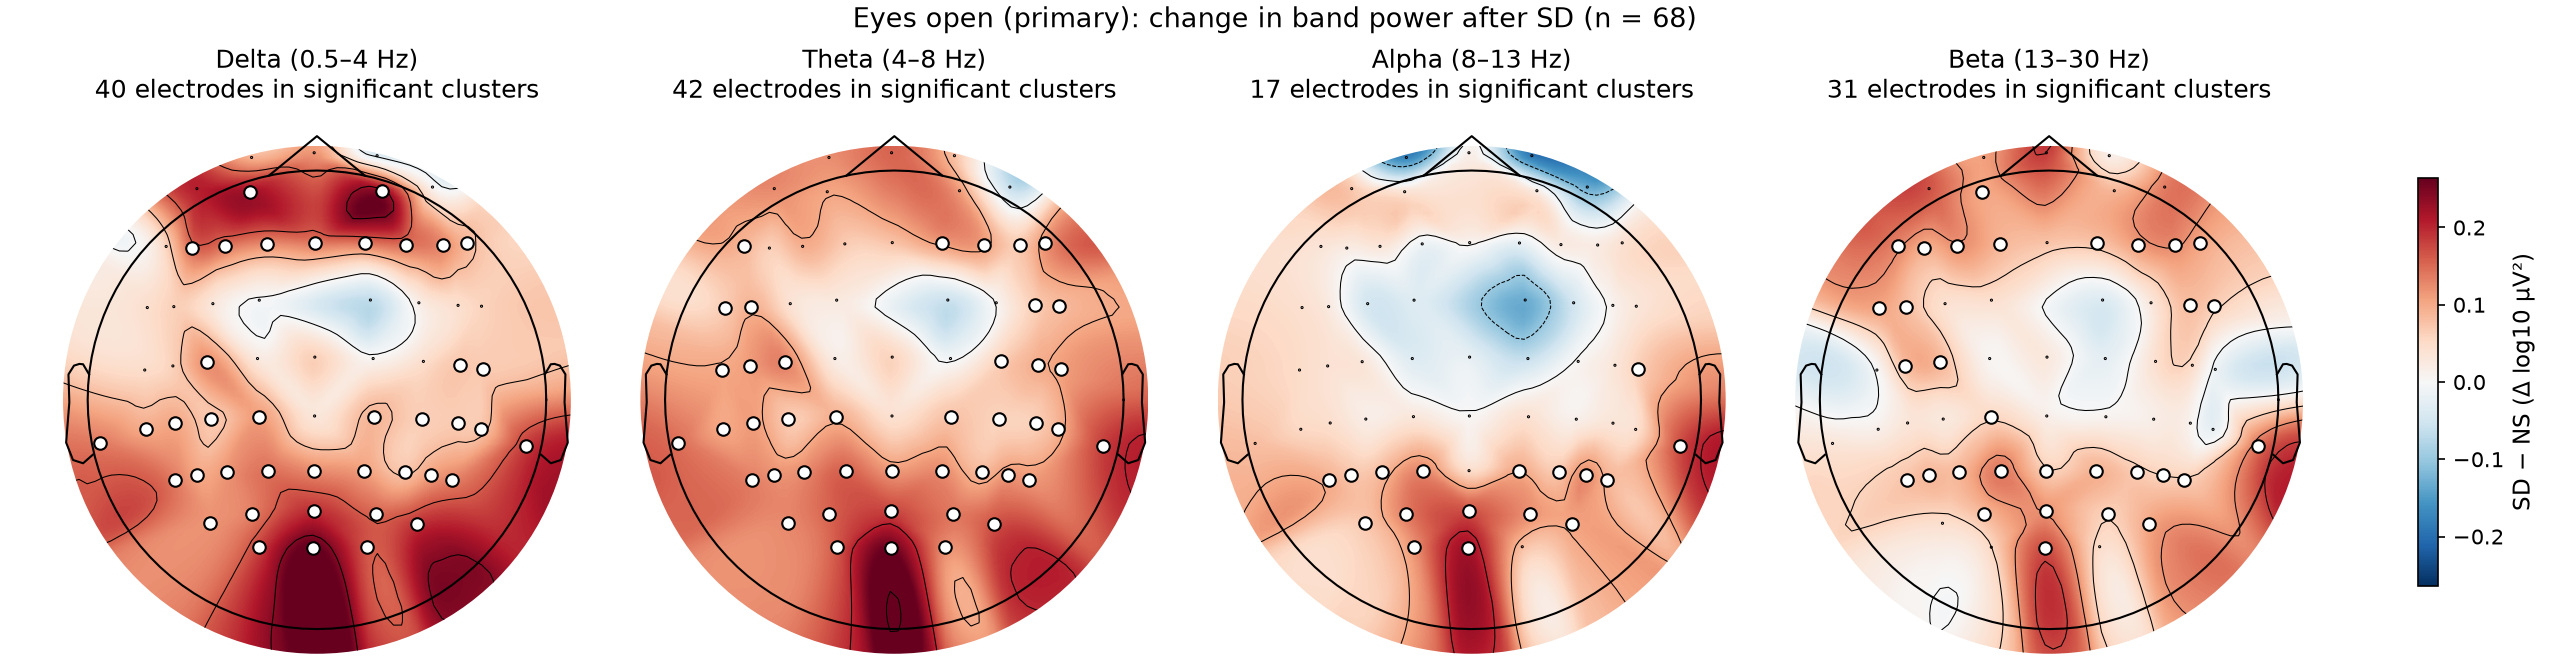



File: `topomap_open.png`

Eyes open (primary). Mean within-participant difference SD − NS of log10 absolute band power (µV²) at each electrode, averaged over participants with both sessions. Red: higher power after SD; blue: lower. One symmetric colour scale for all bands. White dots mark electrodes in clusters with p < .05 in the cluster-based permutation test (5000 sign-flip permutations). Electrode positions: MNE standard 10-05 montage.



In [4]:
display(Image(filename=str(PROJECT / 'results' / 'figures' / 'topomap_open.png')))
display(Markdown(captions.split('## topomap_open')[1].split('## ')[0]))

## Topomaps, eyes closed (secondary)

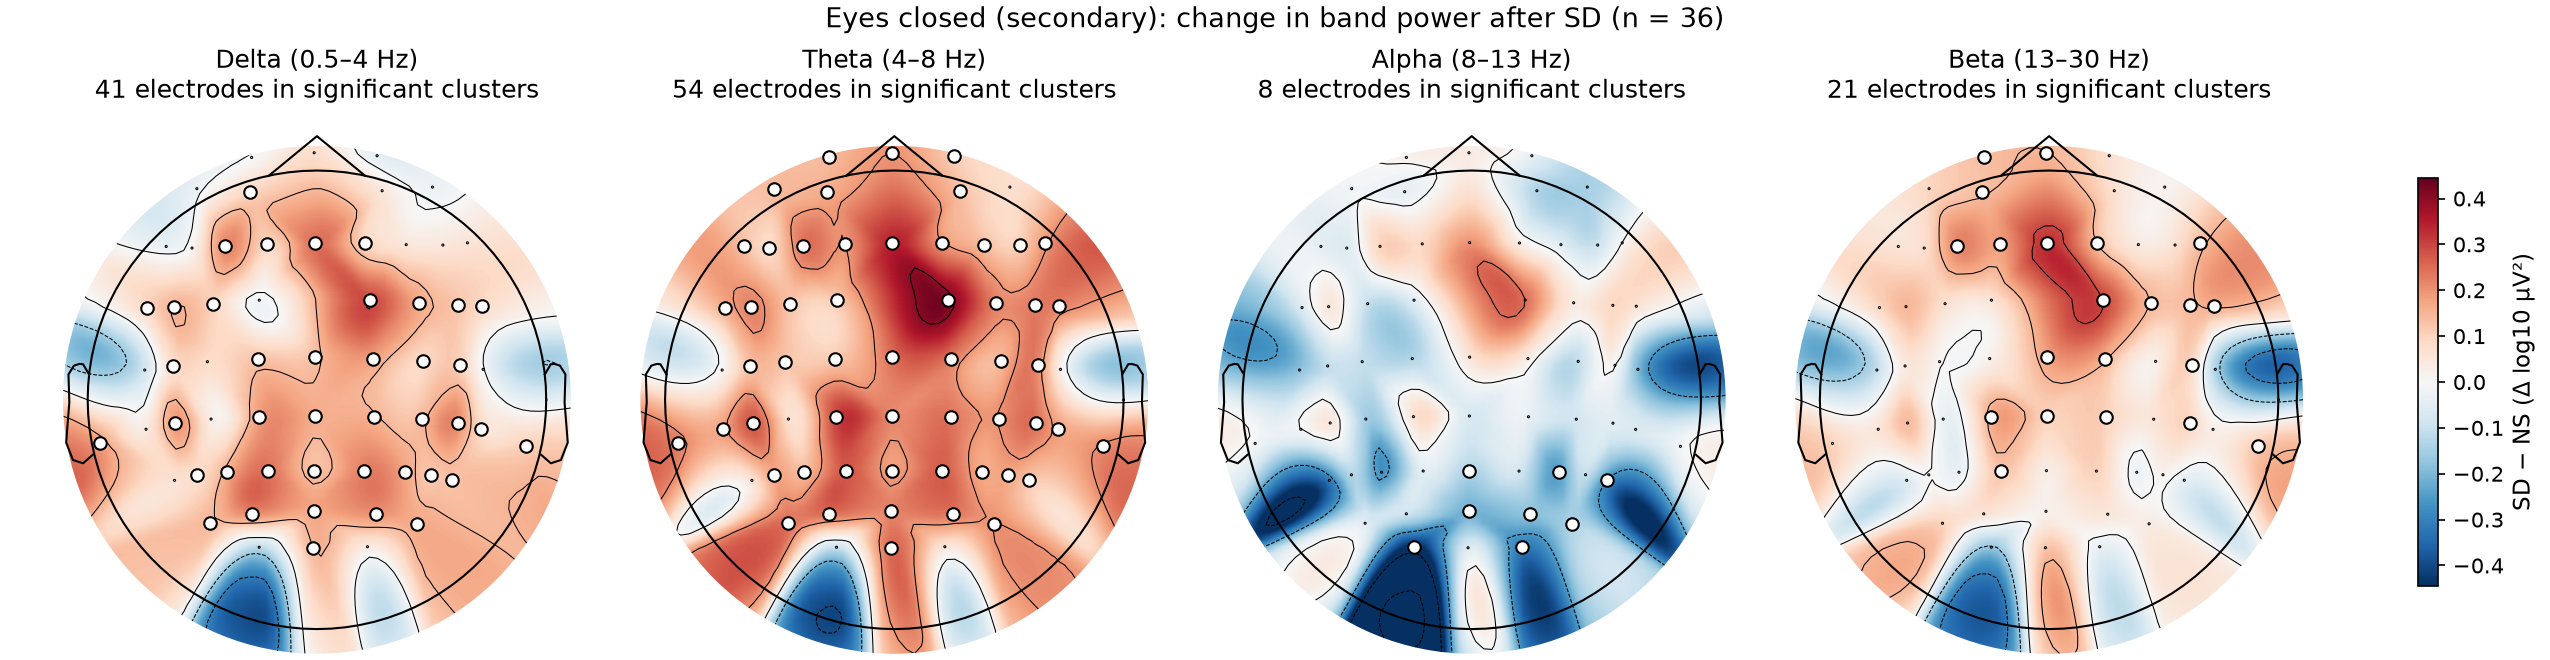



File: `topomap_closed.png`

Eyes closed (secondary). Mean within-participant difference SD − NS of log10 absolute band power (µV²) at each electrode, averaged over participants with both sessions. Red: higher power after SD; blue: lower. One symmetric colour scale for all bands. White dots mark electrodes in clusters with p < .05 in the cluster-based permutation test (5000 sign-flip permutations). Electrode positions: MNE standard 10-05 montage.



In [5]:
display(Image(filename=str(PROJECT / 'results' / 'figures' / 'topomap_closed.png')))
display(Markdown(captions.split('## topomap_closed')[1].split('## ')[0]))

## PSD by region, eyes open

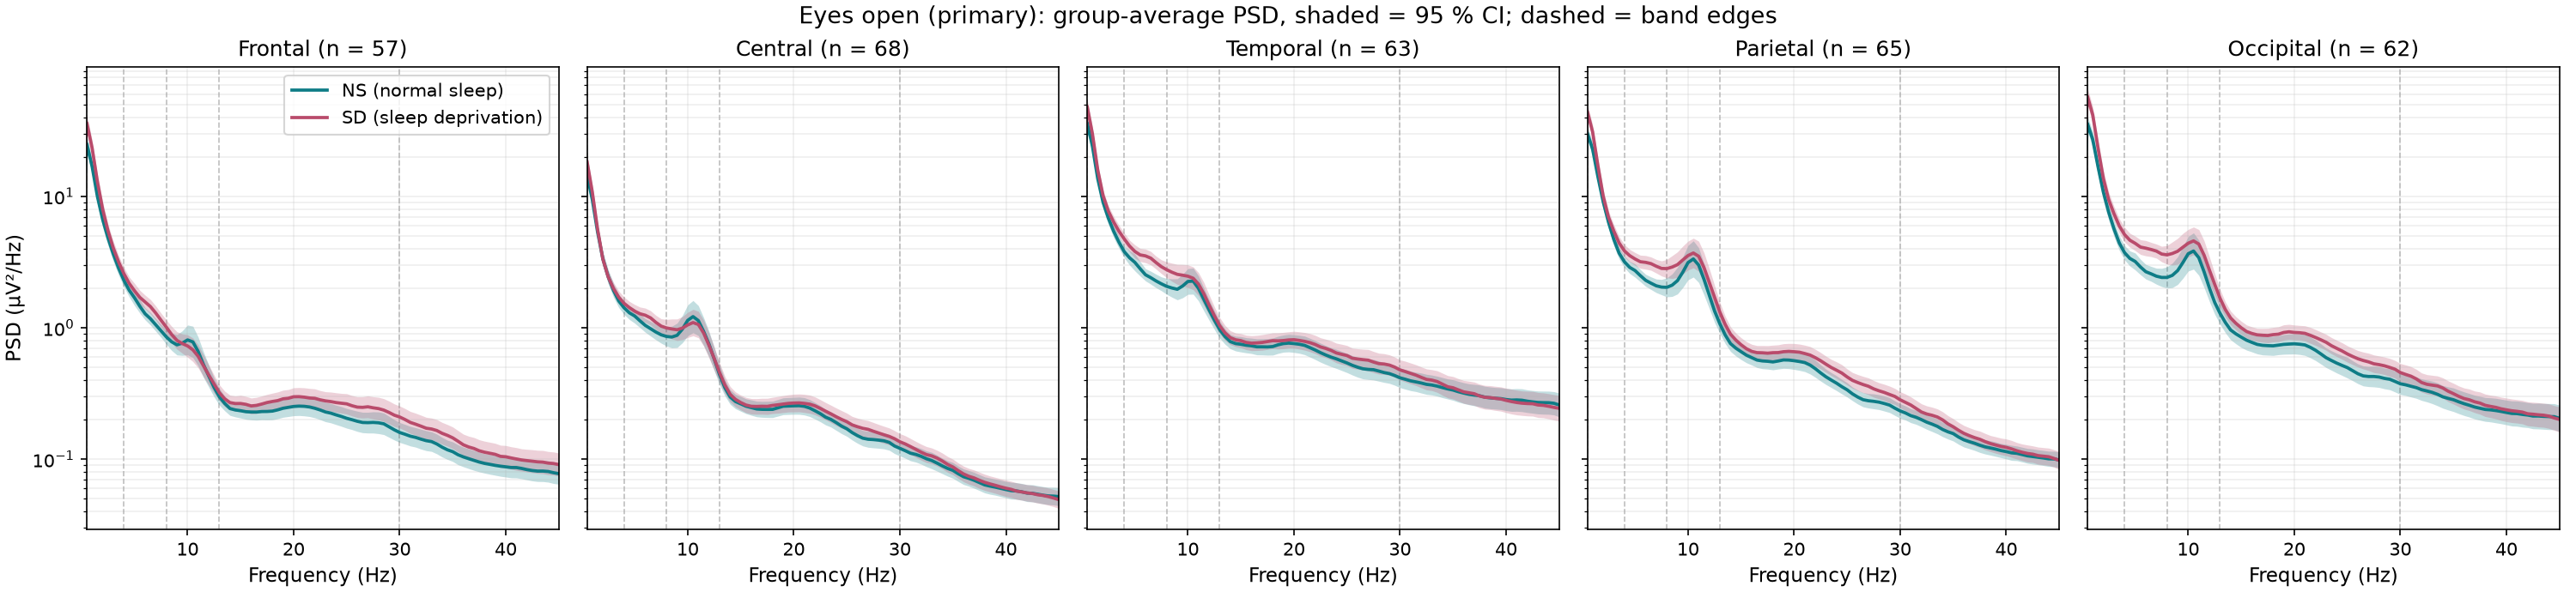



File: `psd_regions_open.png`

Eyes open (primary). Group-average power spectral density per region for NS (teal) and SD (rose): geometric mean over participants of the region-averaged Welch PSD (2 s Hann, 50 % overlap, 0.5 Hz resolution). Shaded areas: 95 % confidence interval of the mean (t-based, on log10 PSD). Dashed lines: band edges (0.5, 4, 8, 13, 30 Hz). Only participants with both sessions and at least half of the region's channels are included.



In [6]:
display(Image(filename=str(PROJECT / 'results' / 'figures' / 'psd_regions_open.png')))
display(Markdown(captions.split('## psd_regions_open')[1].split('## ')[0]))

## PSD by region, eyes closed

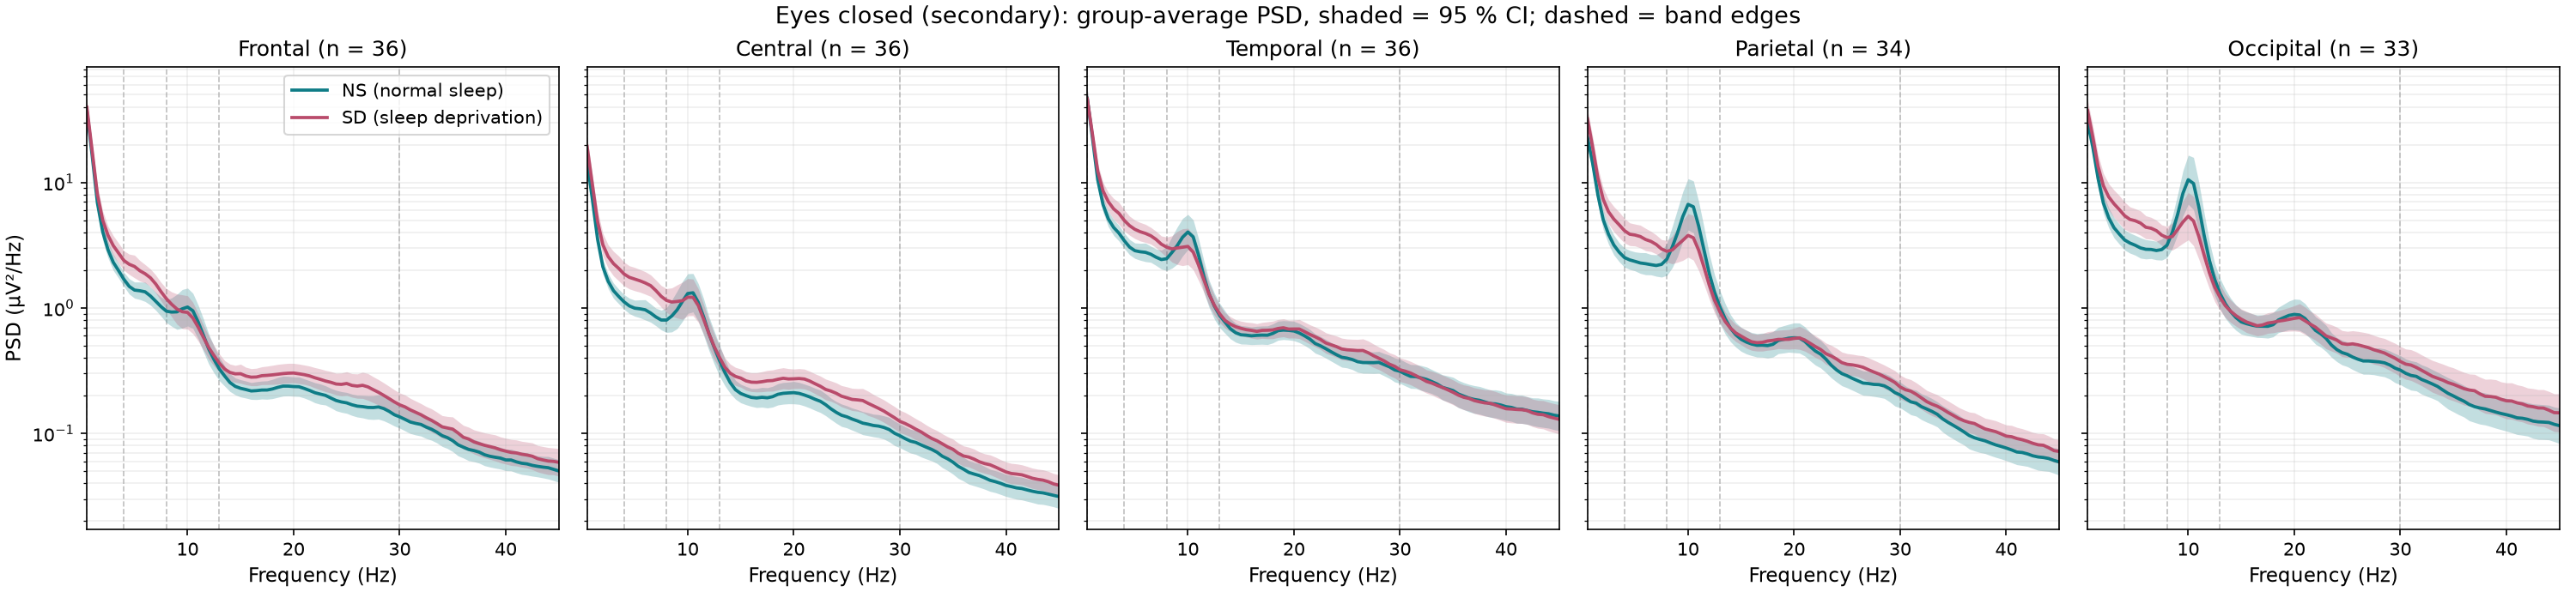



File: `psd_regions_closed.png`

Eyes closed (secondary). Group-average power spectral density per region for NS (teal) and SD (rose): geometric mean over participants of the region-averaged Welch PSD (2 s Hann, 50 % overlap, 0.5 Hz resolution). Shaded areas: 95 % confidence interval of the mean (t-based, on log10 PSD). Dashed lines: band edges (0.5, 4, 8, 13, 30 Hz). Only participants with both sessions and at least half of the region's channels are included.



In [7]:
display(Image(filename=str(PROJECT / 'results' / 'figures' / 'psd_regions_closed.png')))
display(Markdown(captions.split('## psd_regions_closed')[1].split('## ')[0]))

## Paired regional band power, eyes open

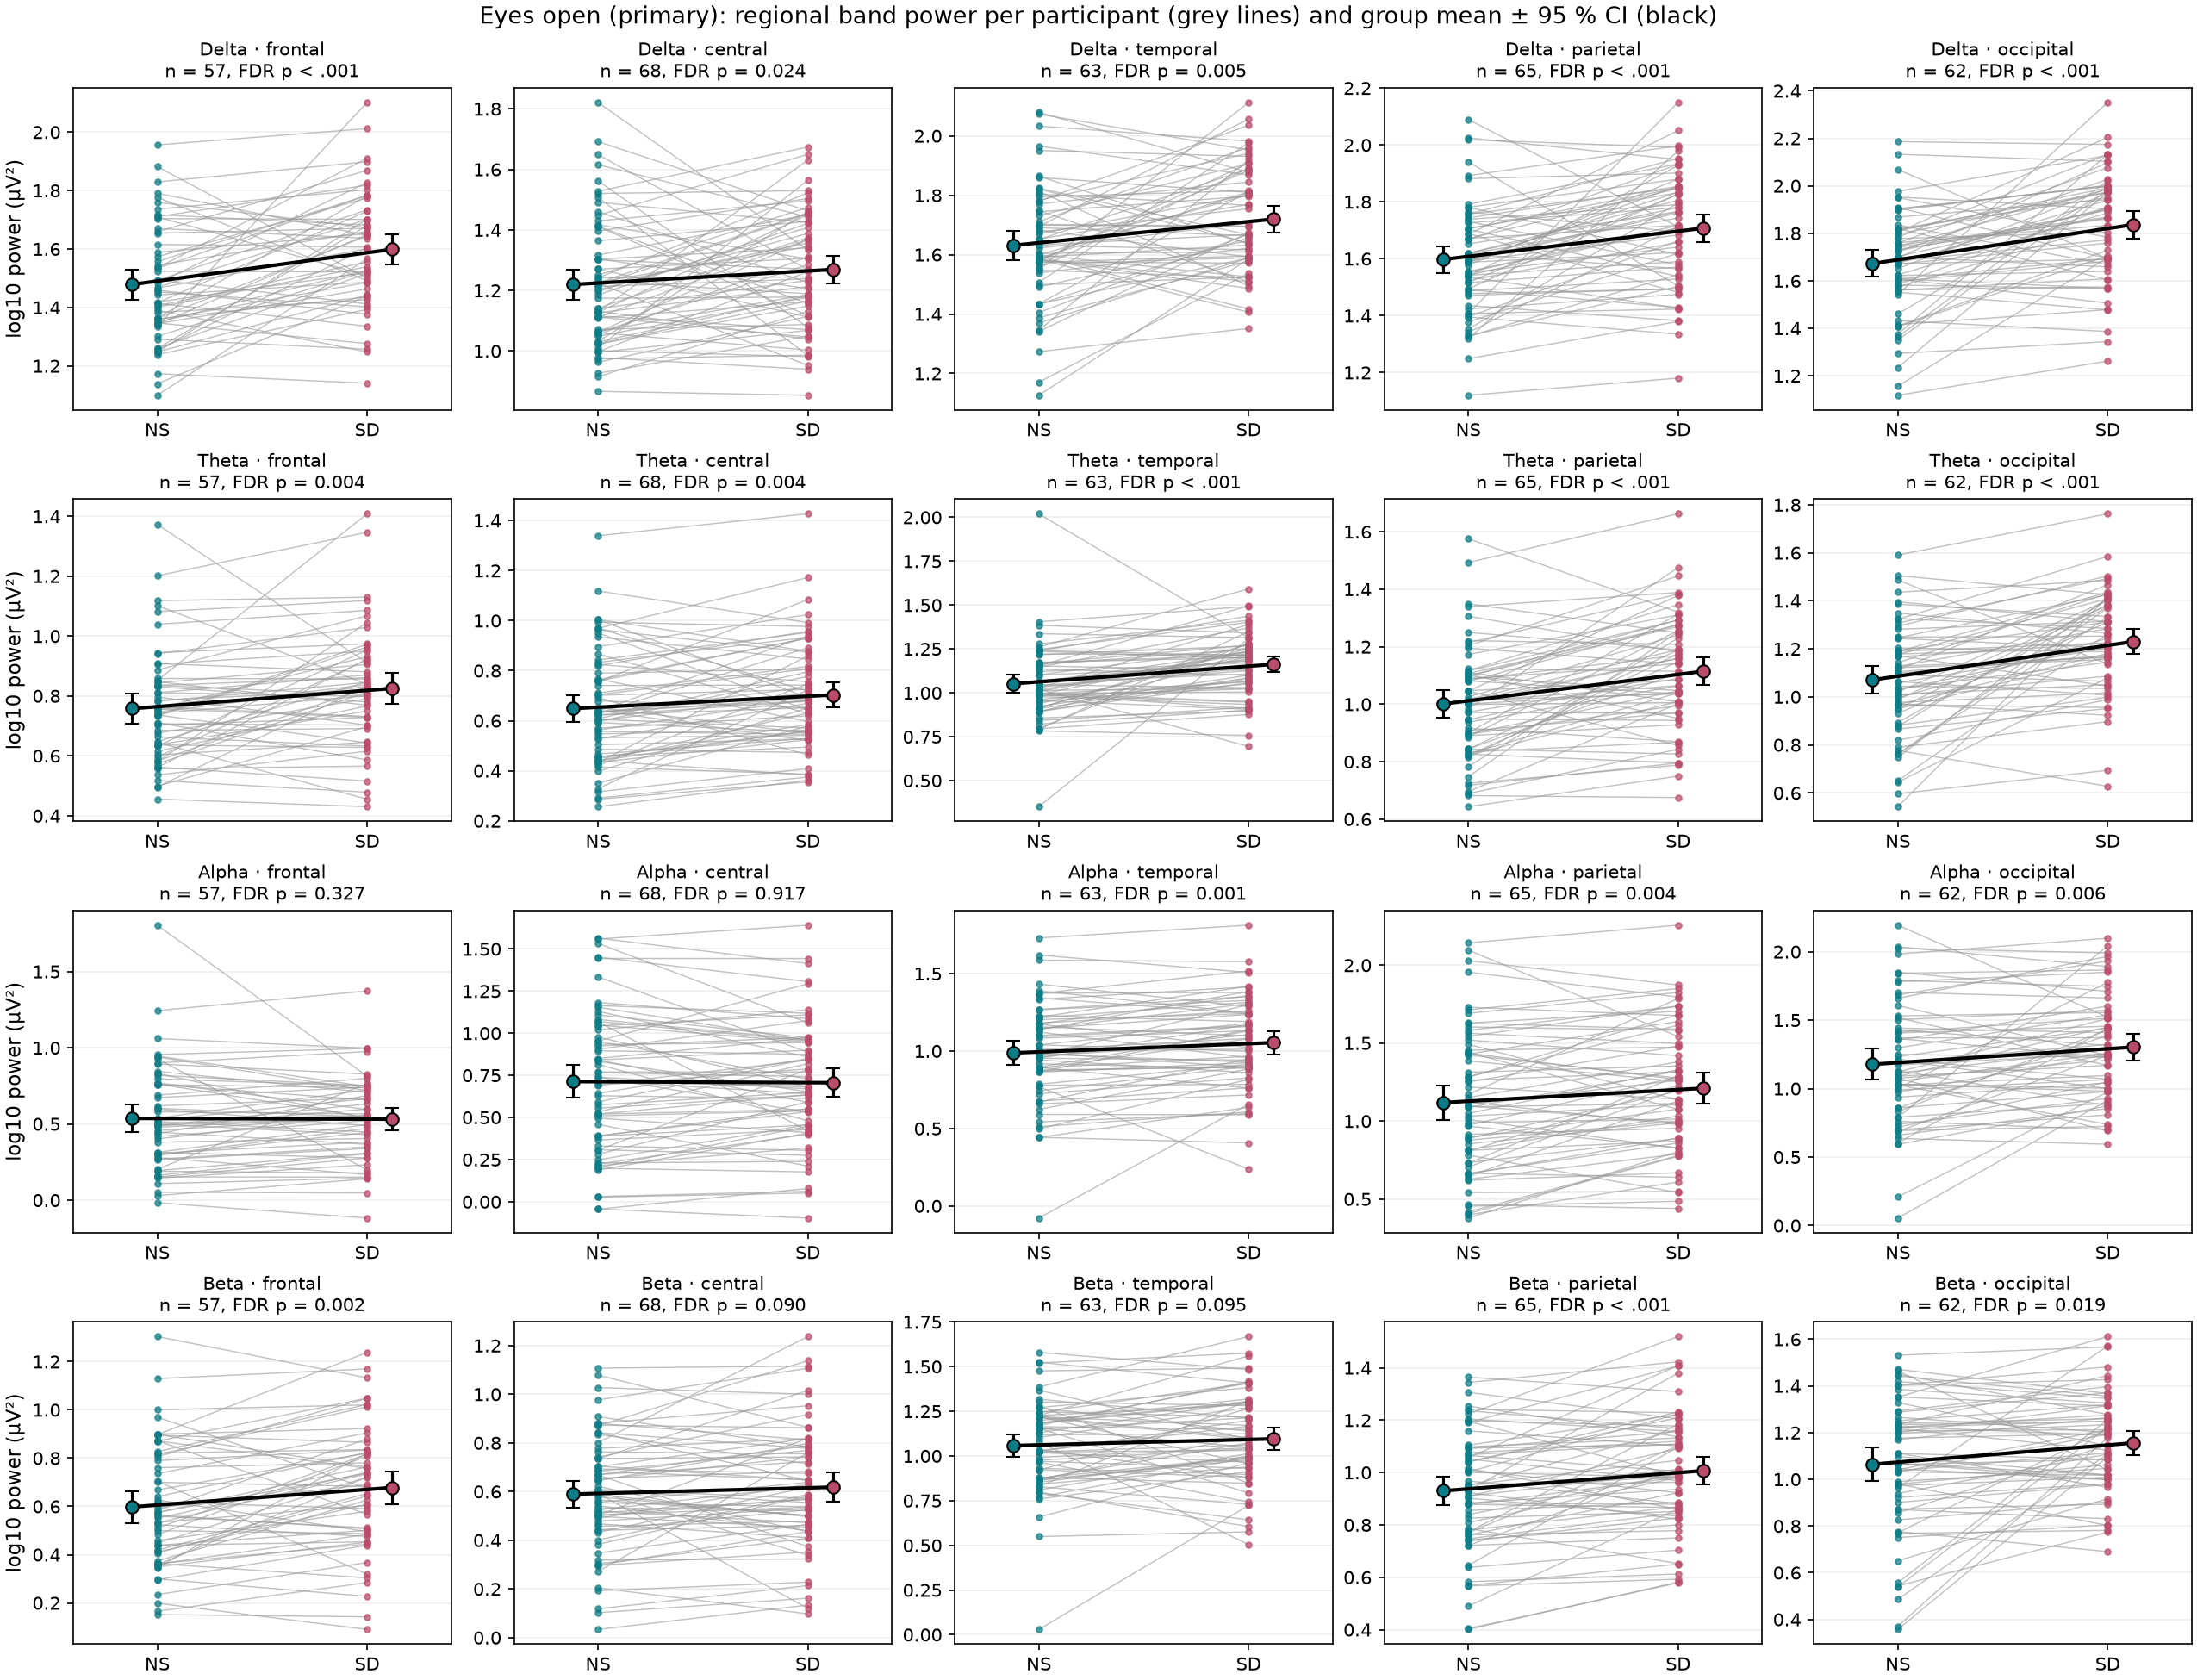



File: `paired_open.png`

Eyes open (primary). Mean log10 absolute power (µV²) per band and region. Grey lines: one participant (NS → SD); coloured points: individual values; black: group mean ± 95 % CI. Panel titles give n and the BH-FDR-corrected Wilcoxon signed-rank p (20 tests per eye condition).



In [8]:
display(Image(filename=str(PROJECT / 'results' / 'figures' / 'paired_open.png')))
display(Markdown(captions.split('## paired_open')[1].split('## ')[0]))

## Paired regional band power, eyes closed

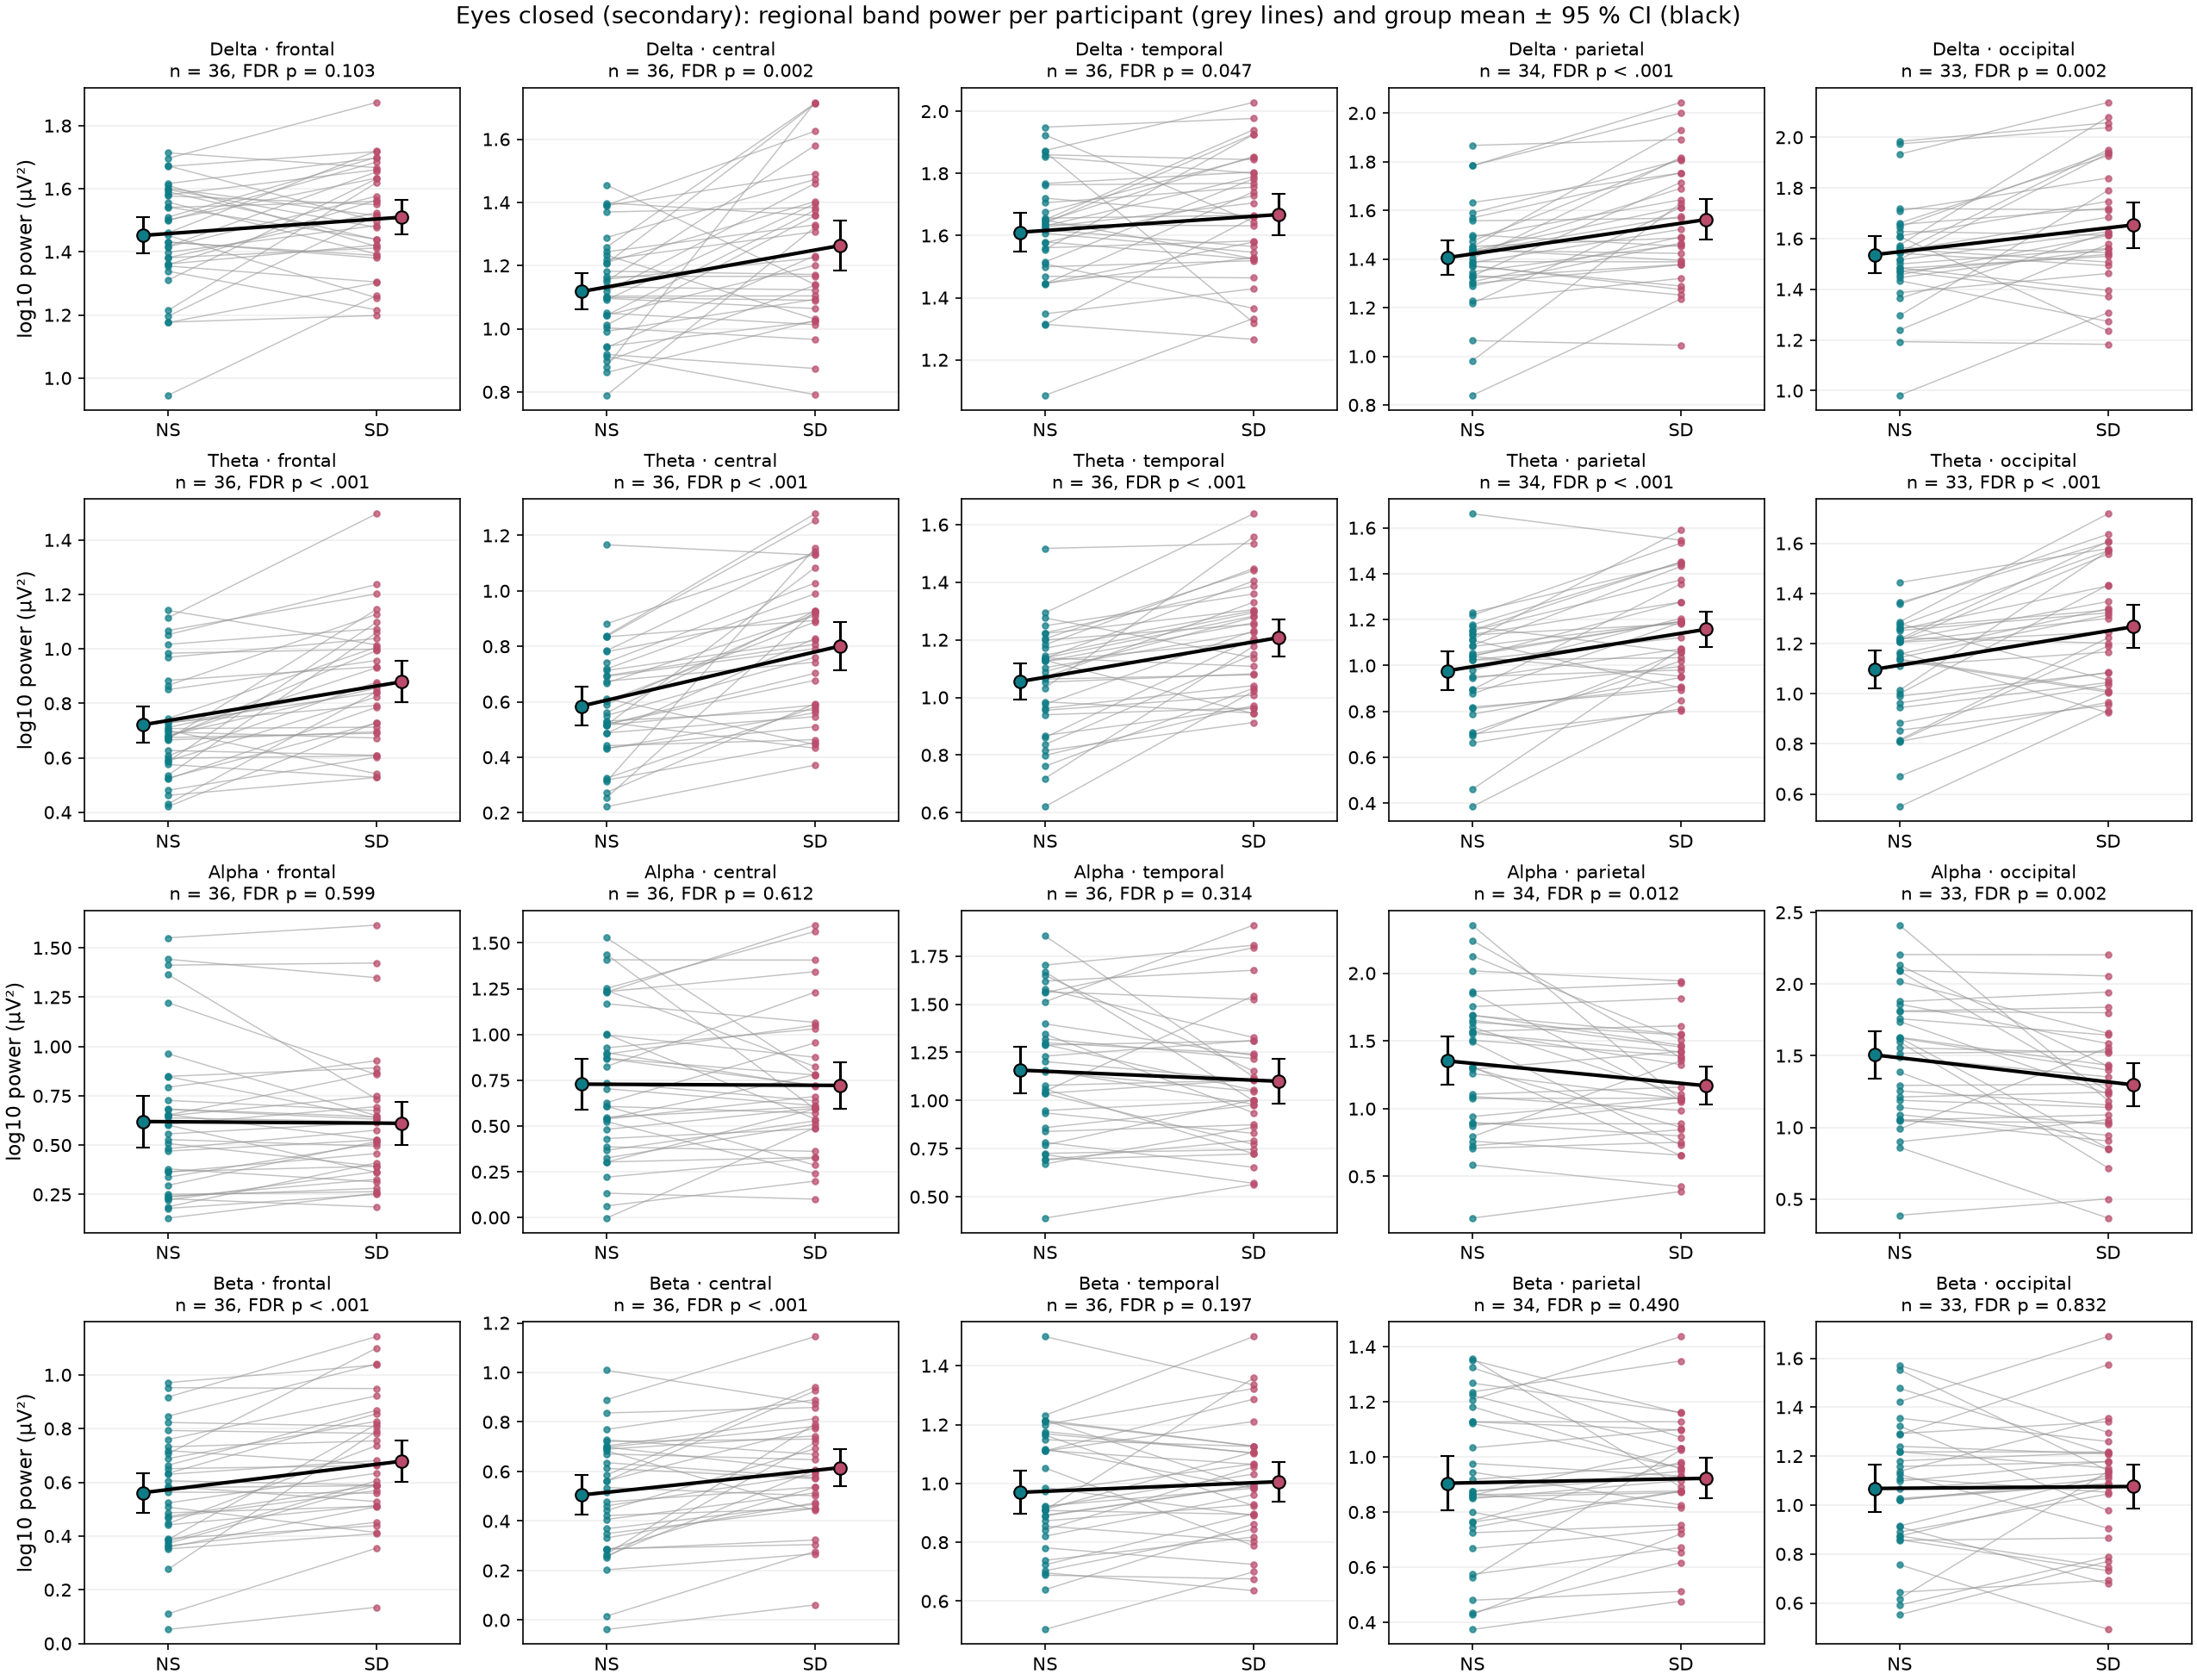



File: `paired_closed.png`

Eyes closed (secondary). Mean log10 absolute power (µV²) per band and region. Grey lines: one participant (NS → SD); coloured points: individual values; black: group mean ± 95 % CI. Panel titles give n and the BH-FDR-corrected Wilcoxon signed-rank p (20 tests per eye condition).



In [9]:
display(Image(filename=str(PROJECT / 'results' / 'figures' / 'paired_closed.png')))
display(Markdown(captions.split('## paired_closed')[1].split('## ')[0]))

## Frontal theta/beta ratio

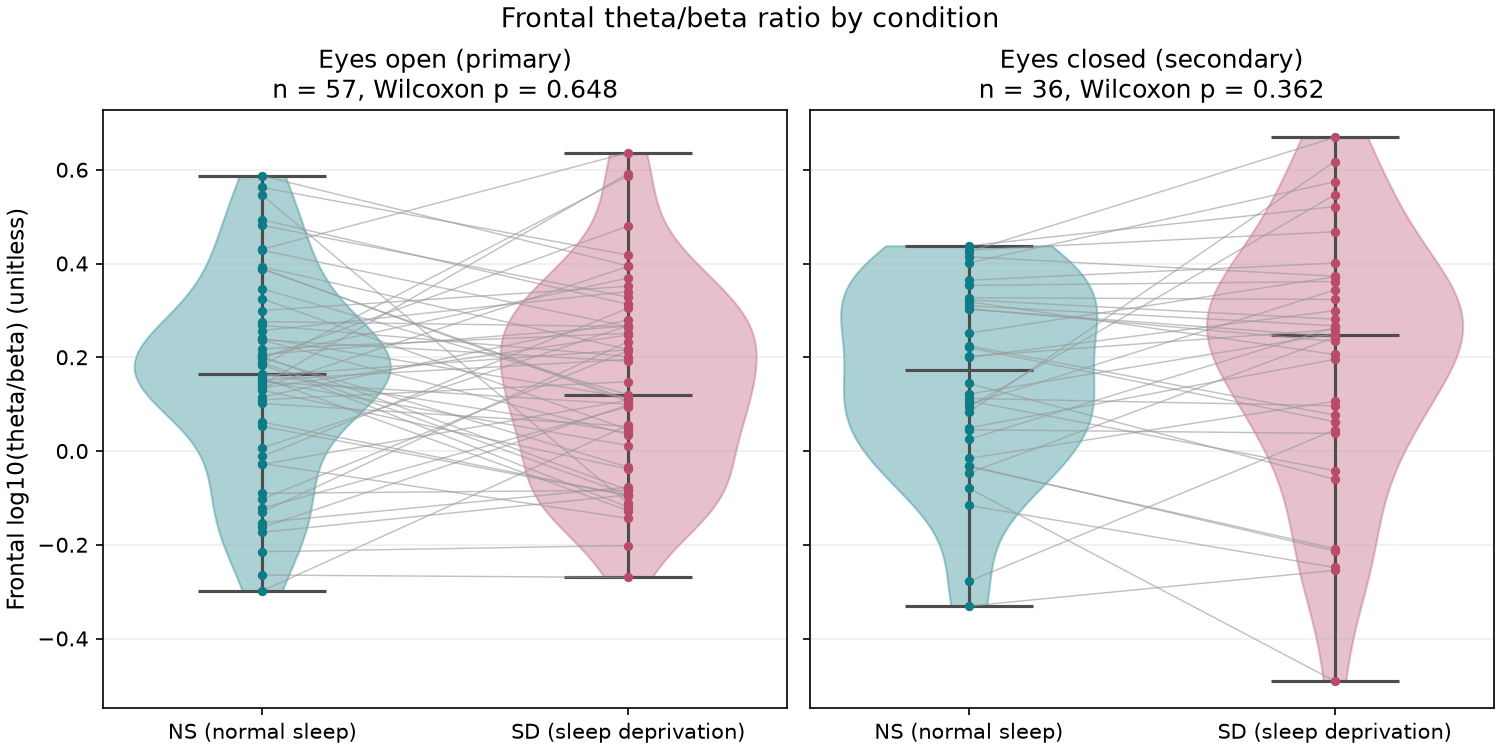



File: `theta_beta.png`

Frontal theta/beta ratio (mean log10 ratio over frontal channels) for NS (teal) and SD (rose), eyes open (primary) and eyes closed (secondary). Violins: distribution; grey lines: one participant; titles: n and Wilcoxon signed-rank p (single pre-specified test, uncorrected).



In [10]:
display(Image(filename=str(PROJECT / 'results' / 'figures' / 'theta_beta.png')))
display(Markdown(captions.split('## theta_beta')[1].split('## ')[0]))